Hover duration: 120.0 s
Maximum altitude error: 0.0000 m
Maximum horizontal drift: 0.0000 m
Hover speed per rotor: 5638 rpm
Hover torque per motor: 0.05703 N·m
Peak electrical power: 234.4 W
Energy used: 7.81 Wh
Usable battery energy consumed: 12.7%


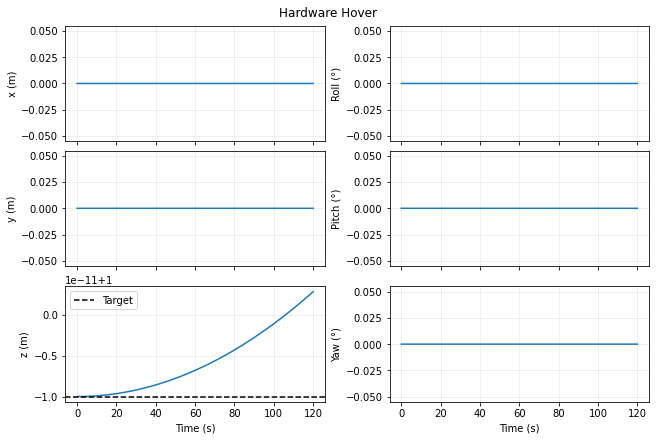

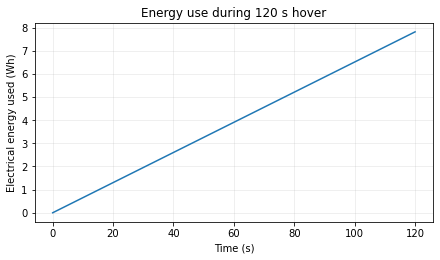

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import cumulative_trapezoid, solve_ivp

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)


def unpack(sol):
    """Read the 16-state solve_ivp output from the quadrotor model."""
    if not sol.success:
        raise RuntimeError(sol.message)

    t = sol.t
    x, y, z = sol.y[0:3]
    vx, vy, vz = sol.y[3:6]
    roll, pitch, yaw = np.rad2deg(sol.y[6:9])

    return t, x, y, z, vx, vy, vz, roll, pitch, yaw


def save_show(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def plot_states(sol, mission, altitude_target=None):
    t, x, y, z, _, _, _, roll, pitch, yaw = unpack(sol)

    fig, axes = plt.subplots(
        3, 2, figsize=(9, 6), sharex=True, constrained_layout=True
    )
    fig.suptitle(mission.replace("_", " ").title())

    traces = [
        (x, "x (m)", roll, "Roll (°)"),
        (y, "y (m)", pitch, "Pitch (°)"),
        (z, "z (m)", yaw, "Yaw (°)"),
    ]

    for row, (position, pos_label, angle, angle_label) in enumerate(traces):
        axes[row, 0].plot(t, position)
        axes[row, 0].set_ylabel(pos_label)
        axes[row, 1].plot(t, angle)
        axes[row, 1].set_ylabel(angle_label)

    if altitude_target is not None:
        axes[2, 0].axhline(
            altitude_target, color="black", linestyle="--", label="Target"
        )
        axes[2, 0].legend()

    for ax in axes.flat:
        ax.grid(alpha=0.25)
    for ax in axes[-1]:
        ax.set_xlabel("Time (s)")

    save_show(fig, f"{mission}_states")


def plot_path_and_speed(sol, mission, circle_center=None, speed_target=None):
    t, x, y, _, vx, vy, *_ = unpack(sol)
    speed = np.hypot(vx, vy)

    fig, (path_ax, speed_ax) = plt.subplots(
        1, 2, figsize=(9, 4), constrained_layout=True
    )

    path_ax.plot(x, y, label="Simulated path")
    path_ax.scatter(x[0], y[0], label="Start", zorder=3)
    path_ax.scatter(x[-1], y[-1], marker="x", label="End", zorder=3)

    if circle_center is not None:
        cx, cy = circle_center
        angle = np.linspace(0, 2 * np.pi, 361)
        path_ax.plot(
            cx + 2.0 * np.cos(angle),
            cy + 2.0 * np.sin(angle),
            "k--",
            label="2 m reference circle",
        )

    path_ax.set(xlabel="x (m)", ylabel="y (m)", title="Top-down flight path")
    path_ax.set_aspect("equal", adjustable="box")
    path_ax.legend()

    speed_ax.plot(t, speed, label="Simulated speed")
    if speed_target is not None:
        speed_ax.axhline(
            speed_target, color="black", linestyle="--", label="Target"
        )
        speed_ax.legend()

    speed_ax.set(xlabel="Time (s)", ylabel="Horizontal speed (m/s)")
    for ax in (path_ax, speed_ax):
        ax.grid(alpha=0.25)

    save_show(fig, f"{mission}_path_and_speed")


def plot_landing(sol, descent_start):
    t, _, _, _, _, _, vz, *_ = unpack(sol)
    descent = t >= descent_start

    if not np.any(descent):
        raise ValueError("Descent starts after the last solver output.")

    fig, ax = plt.subplots(figsize=(6, 3.5), constrained_layout=True)
    ax.plot(t[descent], -vz[descent], label="Simulated downward speed")
    ax.axhline(0.01, color="black", linestyle="--", label="Touchdown limit")
    ax.set(
        xlabel="Time (s)",
        ylabel="Downward speed (m/s)",
        title="Vertical landing",
    )
    ax.grid(alpha=0.25)
    ax.legend()

    save_show(fig, "landing_speed")

def print_hover_metrics(sol):
    t, x, y, z, *_ = unpack(sol)
    drift = np.hypot(x - x[0], y - y[0])

    print(f"Hover duration: {t[-1] - t[0]:.1f} s")
    print(f"Maximum altitude error: {np.max(np.abs(z - 1.0)):.4f} m")
    print(f"Maximum horizontal drift: {np.max(drift):.4f} m")


def print_circle_metrics(sol, circle_center):
    t, x, y, z, vx, vy, *_ = unpack(sol)
    cx, cy = circle_center
    radius = np.hypot(x - cx, y - cy)
    speed = np.hypot(vx, vy)

    print(f"Circular flight duration: {t[-1] - t[0]:.1f} s")
    print(f"Maximum radius error: {np.max(np.abs(radius - 2.0)):.4f} m")
    print(f"Maximum altitude error: {np.max(np.abs(z - 1.0)):.4f} m")
    print(f"Maximum speed error: {np.max(np.abs(speed - 0.5)):.4f} m/s")


mass = 1.700                 # kg
g = 9.80665                  # m/s^2
kT = 1.19582e-5              # N/(rad/s)^2
kQ = 1.63620e-7              # N*m/(rad/s)^2
Jr = 7.20e-5                 # kg*m^2
efficiency = 0.60
aux_power = 10.0             # W
usable_energy = 221644.8     # J

omega_hover = np.sqrt(mass * g / (4 * kT))
torque_hover = kQ * omega_hover**2

initial_state = np.zeros(16)
initial_state[2] = 1.0
initial_state[12:16] = omega_hover


def hover_rhs(t, state):
    """Equations of motion specialized to level, symmetric hover."""
    rotor_speed = state[12:16]
    thrust = kT * np.sum(rotor_speed**2)

    derivative = np.zeros_like(state)
    derivative[0:3] = state[3:6]
    derivative[5] = thrust / mass - g
    derivative[12:16] = (torque_hover - kQ * rotor_speed**2) / Jr

    return derivative


hover_sol = solve_ivp(
    hover_rhs,
    (0.0, 120.0),
    initial_state,
    t_eval=np.linspace(0.0, 120.0, 1201),
    rtol=1e-8,
    atol=1e-10,
)

print_hover_metrics(hover_sol)

rotor_speed = hover_sol.y[12:16]
rotor_rpm = rotor_speed * 60 / (2 * np.pi)
power = torque_hover * np.sum(rotor_speed, axis=0) / efficiency + aux_power
energy = cumulative_trapezoid(power, hover_sol.t, initial=0.0)

print(f"Hover speed per rotor: {rotor_rpm[0, 0]:.0f} rpm")
print(f"Hover torque per motor: {torque_hover:.5f} N·m")
print(f"Peak electrical power: {power.max():.1f} W")
print(f"Energy used: {energy[-1] / 3600:.2f} Wh")
print(f"Usable battery energy consumed: {100 * energy[-1] / usable_energy:.1f}%")

plot_states(hover_sol, "hardware_hover", altitude_target=1.0)

fig, ax = plt.subplots(figsize=(6, 3.5), constrained_layout=True)
ax.plot(hover_sol.t, energy / 3600)
ax.set(
    xlabel="Time (s)",
    ylabel="Electrical energy used (Wh)",
    title="Energy use during 120 s hover",
)
ax.grid(alpha=0.25)
save_show(fig, "hardware_hover_energy")

# The report starts its reference circle at (2, 0) about the origin.
# plot_states(circle_sol, "circle", altitude_target=1.0)
# plot_path_and_speed(
#     circle_sol, "circle", circle_center=(0.0, 0.0), speed_target=0.5
# )
# print_circle_metrics(circle_sol, circle_center=(0.0, 0.0))

# plot_states(maneuver_sol, "takeoff_turn_landing")
# plot_path_and_speed(maneuver_sol, "takeoff_turn_landing")
# plot_landing(maneuver_sol, descent_start=18.0)


SCENARIO 2 — CIRCULAR FLIGHT
Circular flight duration: 60.0 s
Maximum radius error: 0.0000 m
Maximum altitude error: 0.0000 m
Maximum speed error: 0.0000 m/s
Peak electrical power: 234.5 W
Peak estimated battery current: 17.8 A
Peak rotor speed: 590.4 rad/s
Electrical energy used: 3.91 Wh
Usable battery energy consumed: 6.35%


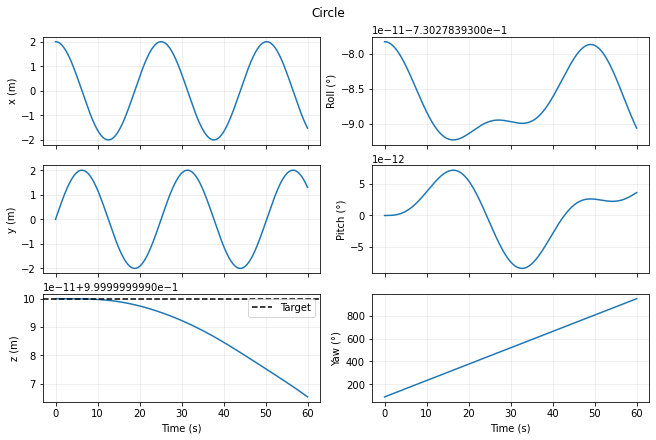

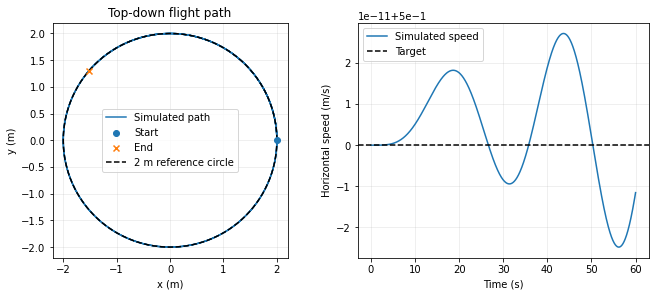


SCENARIO 3 — TAKEOFF, LEFT YAW, AND LANDING
Ground spin-up time: 0.69 s
First-leg forward displacement: 4.976 m
First-leg average horizontal speed: 1.000 m/s
Yaw change over commanded turn: 88.98°
Second-leg leftward displacement: 4.976 m
Touchdown time after spin-up: 21.70 s
Downward touchdown speed: 0.0328 m/s
Meets 0.01 m/s touchdown limit: False
Peak electrical power: 307.1 W
Peak estimated battery current: 23.3 A
Peak rotor speed: 645.1 rad/s
Electrical energy used: 1.46 Wh
Usable battery energy consumed: 2.37%


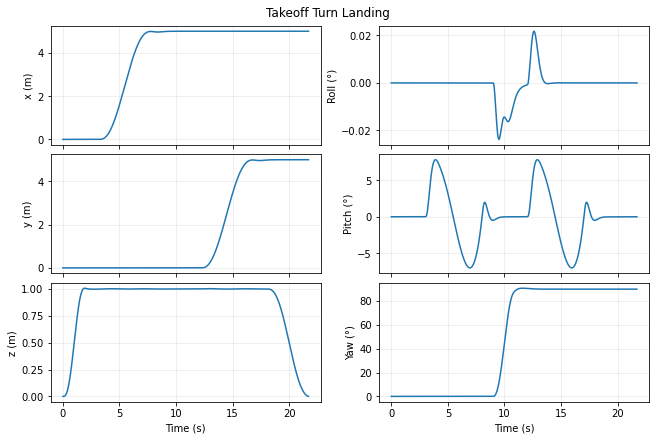

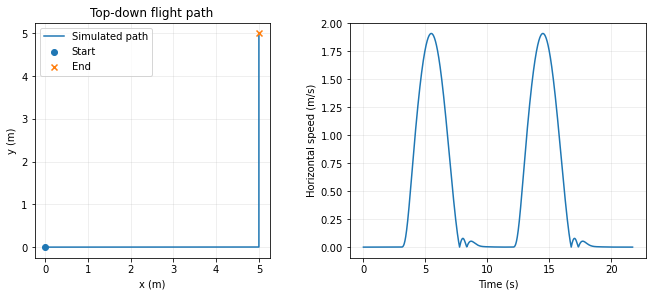

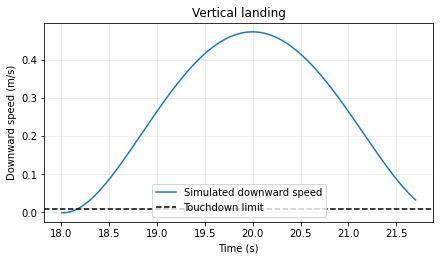

In [5]:

import numpy as np
from scipy.integrate import cumulative_trapezoid, solve_ivp
from scipy.spatial.transform import Rotation

inertia = np.array([0.02006, 0.02006, 0.03083])  # kg m²
arm = 0.250                                     # m, CoM to rotor
offset = arm / np.sqrt(2)
max_motor_torque = 0.10                         # N m per rotor
max_rotor_speed = 700.0                         # rad/s
max_electrical_power = 350.0                    # W
minimum_voltage = 13.2                          # V
max_battery_current = 30.0                      # A


rotor_x = offset * np.array([1, -1, -1, 1])
rotor_y = offset * np.array([-1, -1, 1, 1])
spin = np.array([1, -1, 1, -1])  

allocation = np.vstack([
    np.full(4, kT),
    rotor_y * kT,
    -rotor_x * kT,
    -spin * kQ,
])
inverse_allocation = np.linalg.inv(allocation)


def wrap_angle(angle):
    return np.arctan2(np.sin(angle), np.cos(angle))


def electrical_power(rotor_speed, motor_torque):
    shaft_power = np.maximum(motor_torque * rotor_speed, 0.0)
    return shaft_power.sum() / efficiency + aux_power


def limit_motor_torque(rotor_speed, requested_torque):
    torque = np.clip(requested_torque, 0.0, max_motor_torque)
    power_limit = min(
        max_electrical_power, minimum_voltage * max_battery_current
    )
    shaft_limit = (power_limit - aux_power) * efficiency
    shaft_power = np.dot(torque, rotor_speed)
    if shaft_power > shaft_limit:
        torque *= shaft_limit / shaft_power
    return torque


def flight_rhs(t, state, motor_command):
    roll, pitch, yaw = state[6:9]
    body_rate = state[9:12]
    p, q, r = body_rate
    rotor_speed = state[12:16]
    motor_torque = motor_command(t, state)

    rotor_acceleration = (motor_torque - kQ * rotor_speed**2) / Jr
    thrust, roll_moment, pitch_moment, _ = allocation @ rotor_speed**2

    yaw_moment = -np.dot(spin, motor_torque)
    body_moment = np.array([roll_moment, pitch_moment, yaw_moment])
    rotor_momentum = np.array([0.0, 0.0, Jr * np.dot(spin, rotor_speed)])
    total_momentum = inertia * body_rate + rotor_momentum
    body_acceleration = (
        body_moment - np.cross(body_rate, total_momentum)
    ) / inertia

    rotation = Rotation.from_euler("ZYX", [yaw, pitch, roll])
    acceleration = rotation.apply([0.0, 0.0, thrust / mass])
    acceleration[2] -= g

    qrs = q * np.sin(roll) + r * np.cos(roll)
    euler_rate = [
        p + qrs * np.tan(pitch),
        q * np.cos(roll) - r * np.sin(roll),
        qrs / np.cos(pitch),
    ]
    return np.r_[state[3:6], acceleration, euler_rate,
                 body_acceleration, rotor_acceleration]


def print_energy_metrics(sol, motor_command, initial_energy=0.0):
    power = np.array([
        electrical_power(state[12:16], motor_command(t, state))
        for t, state in zip(sol.t, sol.y.T)
    ])
    energy = initial_energy + cumulative_trapezoid(power, sol.t, initial=0.0)
    print(f"Peak electrical power: {power.max():.1f} W")
    print(f"Peak estimated battery current: {power.max() / minimum_voltage:.1f} A")
    print(f"Peak rotor speed: {sol.y[12:16].max():.1f} rad/s")
    print(f"Electrical energy used: {energy[-1] / 3600:.2f} Wh")
    print(f"Usable battery energy consumed: {100 * energy[-1] / usable_energy:.2f}%")

radius = 2.0
circle_speed = 0.5
orbit_rate = circle_speed / radius
inward_acceleration = circle_speed**2 / radius
bank = -np.arctan2(inward_acceleration, g)
circle_thrust = mass * np.hypot(g, inward_acceleration)

circle_body_rate = np.array([
    0.0,
    orbit_rate * np.sin(bank),
    orbit_rate * np.cos(bank),
])

circle_moment = np.cross(circle_body_rate, inertia * circle_body_rate)
circle_rotor_speed = np.sqrt(
    inverse_allocation @ np.r_[circle_thrust, circle_moment]
)
circle_motor_torque = kQ * circle_rotor_speed**2


def circle_command(t, state):
    return circle_motor_torque


circle_initial = np.r_[
    [radius, 0.0, 1.0],
    [0.0, circle_speed, 0.0],
    [bank, 0.0, np.pi / 2],
    circle_body_rate,
    circle_rotor_speed,
]

circle_sol = solve_ivp(
    lambda t, state: flight_rhs(t, state, circle_command),
    (0.0, 60.0),
    circle_initial,
    t_eval=np.linspace(0.0, 60.0, 1201),
    max_step=0.05,
    rtol=1e-9,
    atol=1e-11,
)

print("\nSCENARIO 2 — CIRCULAR FLIGHT")
print_circle_metrics(circle_sol, circle_center=(0.0, 0.0))
print_energy_metrics(circle_sol, circle_command)
plot_states(circle_sol, "circle", altitude_target=1.0)
plot_path_and_speed(
    circle_sol, "circle", circle_center=(0.0, 0.0), speed_target=0.5
)



def smooth_move(t, start, end):
    """Quintic progress and its first two time derivatives."""
    duration = end - start
    u = np.clip((t - start) / duration, 0.0, 1.0)
    progress = u**3 * (10 - 15*u + 6*u**2)
    speed = 30*u**2 * (1-u)**2 / duration
    acceleration = 60*u * (1-u) * (1-2*u) / duration**2
    return np.array([progress, speed, acceleration])


def waypoint_reference(t):
    x = 5.0 * smooth_move(t, 3.0, 8.0)
    y = 5.0 * smooth_move(t, 12.0, 17.0)
    z = smooth_move(t, 0.0, 2.0) - smooth_move(t, 18.0, 22.0)


    if t >= 18.0:
        z -= 0.003 * smooth_move(t, 18.0, 22.0)
    if t > 22.0:
        z -= np.array([0.003 * (t - 22.0), 0.003, 0.0])

    yaw = (np.pi / 2) * smooth_move(t, 9.0, 11.0)
    position, velocity, acceleration = np.array([x, y, z]).T
    return position, velocity, acceleration, yaw


def waypoint_command(t, state):
    position, velocity, acceleration, yaw_ref = waypoint_reference(t)
    roll, pitch, yaw = state[6:9]
    body_rate = state[9:12]
    rotor_speed = state[12:16]

    desired_acceleration = (
        acceleration + 4.0 * (position - state[:3])
        + 3.5 * (velocity - state[3:6])
    )
    desired_acceleration[:2] = np.clip(desired_acceleration[:2], -2.5, 2.5)
    desired_acceleration[2] = np.clip(desired_acceleration[2], -3.0, 3.0)
    force_per_mass = desired_acceleration + np.array([0.0, 0.0, g])
    thrust_direction = force_per_mass / np.linalg.norm(force_per_mass)


    direction = Rotation.from_euler("z", -yaw).apply(thrust_direction)
    roll_ref = -np.arcsin(np.clip(direction[1], -1.0, 1.0))
    pitch_ref = np.arctan2(direction[0], direction[2])
    angle_error = np.array([
        roll_ref - roll,
        pitch_ref - pitch,
        wrap_angle(yaw_ref[0] - yaw),
    ])


    desired_rate = np.array([0.0, 0.0, yaw_ref[1]])
    angular_acceleration = (
        np.array([100.0, 100.0, 25.0]) * angle_error
        + np.array([16.0, 16.0, 9.0]) * (desired_rate - body_rate)
        + np.array([0.0, 0.0, yaw_ref[2]])
    )
    desired_moment = (
        inertia * angular_acceleration
        + np.cross(body_rate, inertia * body_rate)
    )

    thrust = mass * np.linalg.norm(force_per_mass)
    desired_speed_squared = inverse_allocation @ np.r_[thrust, desired_moment]
    desired_speed = np.sqrt(
        np.clip(desired_speed_squared, 0.0, max_rotor_speed**2)
    )
   
    requested_torque = (
        kQ * rotor_speed**2 + Jr * 45.0 * (desired_speed - rotor_speed)
    )
    return limit_motor_torque(rotor_speed, requested_torque)


spinup_torque = min(max_motor_torque, (350.0 - aux_power)
                    * efficiency / (4 * omega_hover))


def lift_off_speed(t, rotor_speed):
    return rotor_speed[0] - omega_hover


lift_off_speed.terminal = True
lift_off_speed.direction = 1

spinup_sol = solve_ivp(
    lambda t, speed: [(spinup_torque - kQ * speed[0]**2) / Jr],
    (0.0, 5.0),
    [0.0],
    events=lift_off_speed,
    max_step=0.01,
    rtol=1e-8,
    atol=1e-10,
)

if not spinup_sol.success or spinup_sol.t_events[0].size == 0:
    raise RuntimeError("The rotors did not reach hover speed during ground spin-up.")

spinup_power = 4.0 * spinup_torque * spinup_sol.y[0] / efficiency + aux_power
spinup_energy = cumulative_trapezoid(
    spinup_power, spinup_sol.t, initial=0.0
)[-1]

waypoint_initial = np.zeros(16)
waypoint_initial[12:16] = spinup_sol.y_events[0][0, 0]


def ground_contact(t, state):
    return state[2] if t >= 18.0 else 1.0


ground_contact.terminal = True
ground_contact.direction = -1

maneuver_sol = solve_ivp(
    lambda t, state: flight_rhs(t, state, waypoint_command),
    (0.0, 26.0),
    waypoint_initial,
    events=ground_contact,
    dense_output=True,
    max_step=0.02,
    rtol=1e-7,
    atol=1e-9,
)

if not maneuver_sol.success:
    raise RuntimeError(maneuver_sol.message)

print("\nSCENARIO 3 — TAKEOFF, LEFT YAW, AND LANDING")
print(f"Ground spin-up time: {spinup_sol.t[-1]:.2f} s")

leg_start = maneuver_sol.sol(3.0)
leg_end = maneuver_sol.sol(8.0)
leg_samples = maneuver_sol.sol(np.linspace(3.0, 8.0, 501))
leg_distance = cumulative_trapezoid(
    np.hypot(leg_samples[3], leg_samples[4]),
    np.linspace(3.0, 8.0, 501),
    initial=0.0,
)[-1]
yaw_change = maneuver_sol.sol(11.0)[8] - maneuver_sol.sol(9.0)[8]

print(f"First-leg forward displacement: {leg_end[0] - leg_start[0]:.3f} m")
print(f"First-leg average horizontal speed: {leg_distance / 5.0:.3f} m/s")
print(f"Yaw change over commanded turn: {np.rad2deg(yaw_change):.2f}°")
print(f"Second-leg leftward displacement: "
      f"{maneuver_sol.sol(17.0)[1] - maneuver_sol.sol(12.0)[1]:.3f} m")

if maneuver_sol.t_events[0].size:
    touchdown_time = maneuver_sol.t_events[0][0]
    touchdown_speed = -maneuver_sol.y_events[0][0, 5]
    print(f"Touchdown time after spin-up: {touchdown_time:.2f} s")
    print(f"Downward touchdown speed: {touchdown_speed:.4f} m/s")
    print(f"Meets 0.01 m/s touchdown limit: {touchdown_speed <= 0.01}")
else:
    print("Ground contact was not reached within the simulated time.")

print_energy_metrics(maneuver_sol, waypoint_command, initial_energy=spinup_energy)
plot_states(maneuver_sol, "takeoff_turn_landing")
plot_path_and_speed(maneuver_sol, "takeoff_turn_landing")
plot_landing(maneuver_sol, descent_start=18.0)